# 11 — Hybrid (XGBoost + LSTM)

Stage 12. The gradient-boosting and LSTM forecasts make partly different errors, so
a convex blend `w*xgb + (1-w)*lstm` can beat either alone. The weight `w` is chosen on
the 2013 validation year and frozen for the 2014 test (`src/hybrid.py`), so the test is
never used to build the hybrid. This is the optional hybrid step of Phase 2.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, validate
from src import windows as W
from src.dl_models import LSTMForecaster
from src.evaluate import metrics, diebold_mariano
from src.hybrid import best_blend_weight, blend
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
cfg = json.load(open(ROOT / 'results' / 'metrics' / 'lstm_selected_config.json'))
params = {k: cfg[k] for k in ['formulation', 'hidden', 'layers', 'dropout', 'lr', 'weight_decay', 'epochs', 'seed']}

## 1. Do the two models make different errors?

A blend only helps when the errors are not identical. Regenerate the LSTM validation
forecast, line it up with the saved XGBoost validation forecast, and look at the
correlation of their errors.

In [2]:
X, y, split, mask, stats = W.build_sequence_dataset(df, lookback=cfg['lookback'])
pm_t = df['pm25'].ffill().reindex(mask.index).to_numpy('float32')
sp, mk = split.to_numpy(), mask.to_numpy()
tr = (sp == 'train') & ~np.isnan(y) & ~np.isnan(pm_t)
ve = (sp == 'val') & mk

lstm_val = pd.Series(LSTMForecaster(**params).fit(X[tr], y[tr], pm_t[tr]).predict(X[ve], pm_t[ve]),
                     index=mask.index[ve], name='lstm')
xv = pd.read_csv(ROOT / 'results' / 'predictions' / 'xgb_val_folds.csv', parse_dates=['issue_time']).set_index('issue_time')
v = xv.join(lstm_val).dropna()
yv = v['y_true'].to_numpy()

e_xgb, e_lstm = yv - v['xgboost'].to_numpy(), yv - v['lstm'].to_numpy()
print('validation error correlation (xgb, lstm):', round(float(np.corrcoef(e_xgb, e_lstm)[0, 1]), 3))

validation error correlation (xgb, lstm): 0.945


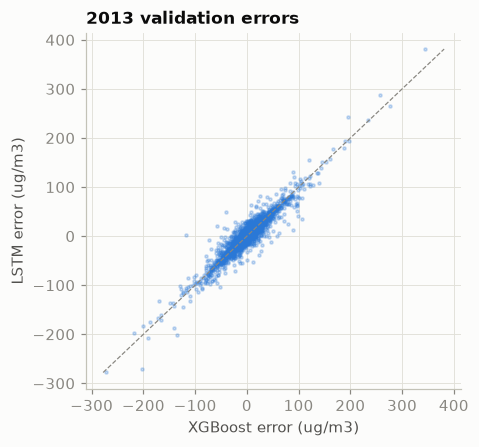

In [3]:
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(e_xgb, e_lstm, s=4, alpha=0.25, color=ps.PRIMARY)
lim = np.array([min(e_xgb.min(), e_lstm.min()), max(e_xgb.max(), e_lstm.max())])
ax.plot(lim, lim, color=ps.MUTED, lw=0.8, ls='--')
ax.set_xlabel('XGBoost error (ug/m3)'); ax.set_ylabel('LSTM error (ug/m3)')
ax.set_title('2013 validation errors')
ps.save(fig, 'dl_05_error_scatter'); plt.show()

## 2. Blend weight (fit on 2013)

`w` minimises the squared error of the blend on the validation year.

In [4]:
w = best_blend_weight(yv, v['xgboost'], v['lstm'])
hyb_val = blend(v['xgboost'], v['lstm'], w)
val_tbl = pd.DataFrame([
    {'model': 'XGBoost', **metrics(yv, v['xgboost'])},
    {'model': 'LSTM', **metrics(yv, v['lstm'])},
    {'model': 'Hybrid', **metrics(yv, hyb_val)},
]).set_index('model')[['MAE', 'RMSE', 'R2']]

json.dump({'w_xgb': round(float(w), 4), 'w_lstm': round(1 - float(w), 4),
           'tuned_on': '2013 validation', 'val_MAE': float(metrics(yv, hyb_val)['MAE']),
           'val_RMSE': float(metrics(yv, hyb_val)['RMSE'])},
          open(ROOT / 'results' / 'metrics' / 'hybrid_weight.json', 'w'), indent=2)
print(f'w = {w:.3f} on XGBoost, {1-w:.3f} on LSTM')
val_tbl.round(3)

w = 0.630 on XGBoost, 0.370 on LSTM


,MAE,RMSE,R2
model,,,
XGBoost,12.258,22.526,0.947
LSTM,12.471,22.849,0.946
Hybrid,12.117,22.354,0.948


## 3. 2014 test with the frozen weight

Apply the same `w` to the saved 2014 test forecasts. The hybrid is scored on the same
eval hours as every other model.

In [5]:
t = pd.read_csv(ROOT / 'results' / 'predictions' / 'lstm_test_2014.csv', parse_dates=['target_time'])
yt = t['y_true'].to_numpy()
t['hybrid'] = blend(t['xgboost'], t['lstm'], w)
t[['target_time', 'y_true', 'xgboost', 'lstm', 'hybrid']].to_csv(
    ROOT / 'results' / 'predictions' / 'hybrid_test_2014.csv', index=False)

test_tbl = pd.DataFrame([
    {'model': 'persistence', **metrics(yt, t['persistence'])},
    {'model': 'XGBoost', **metrics(yt, t['xgboost'])},
    {'model': 'LSTM', **metrics(yt, t['lstm'])},
    {'model': 'Hybrid', **metrics(yt, t['hybrid'])},
]).set_index('model')[['n', 'MAE', 'RMSE', 'R2']]
test_tbl.to_csv(ROOT / 'results' / 'metrics' / 'hybrid_test_pooled.csv')
test_tbl.round(3)

,n,MAE,RMSE,R2
model,,,,
persistence,8531,11.926,22.033,0.944
XGBoost,8531,10.959,19.956,0.954
LSTM,8531,11.279,20.493,0.952
Hybrid,8531,10.902,19.894,0.955


## 4. Is the hybrid gain real?

Diebold–Mariano of the hybrid against XGBoost on the 2014 eval hours. A negative
statistic means the hybrid has the lower loss.

In [6]:
dm = []
for loss in ['squared', 'absolute']:
    stat, p = diebold_mariano(yt - t['hybrid'].to_numpy(), yt - t['xgboost'].to_numpy(), loss=loss)
    dm.append({'comparison': 'Hybrid vs XGBoost', 'loss': loss, 'DM': stat, 'p-value': p})
dm = pd.DataFrame(dm)
dm.to_csv(ROOT / 'results' / 'metrics' / 'hybrid_diebold_mariano.csv', index=False)
dm.round(4)

,comparison,loss,DM,p-value
0,Hybrid vs XGBoost,squared,-0.5994,0.5489
1,Hybrid vs XGBoost,absolute,-1.8175,0.0691


## 5. Test error by PM2.5 level

Where does the blend help, and where does the extreme-hour wall remain?

In [7]:
bands = pd.cut(t['y_true'], [0, 35, 75, 150, 250, np.inf],
               labels=['0-35', '35-75', '75-150', '150-250', '>250'])
def band_rows(g):
    yy = g['y_true'].to_numpy()
    return pd.Series({'hours': len(g),
                      'MAE xgb': metrics(yy, g['xgboost'])['MAE'],
                      'MAE lstm': metrics(yy, g['lstm'])['MAE'],
                      'MAE hybrid': metrics(yy, g['hybrid'])['MAE']})
by_level = t.groupby(bands, observed=True).apply(band_rows)
by_level.to_csv(ROOT / 'results' / 'metrics' / 'hybrid_test_by_level.csv')
by_level.round(2)

,hours,MAE xgb,MAE lstm,MAE hybrid
y_true,,,,
0-35,2485.0,5.48,5.86,5.55
35-75,1937.0,9.39,9.75,9.43
75-150,2399.0,11.82,11.95,11.69
150-250,1061.0,16.78,17.29,16.62
>250,649.0,23.92,24.28,23.53


## 6. Summary figure

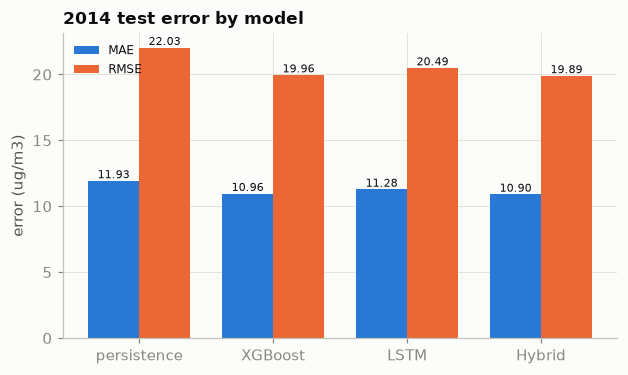

In [8]:
models = ['persistence', 'XGBoost', 'LSTM', 'Hybrid']
mae = [test_tbl.loc[m, 'MAE'] for m in models]
rmse = [test_tbl.loc[m, 'RMSE'] for m in models]
xpos = np.arange(len(models)); width = 0.38
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(xpos - width/2, mae, width, color=ps.SERIES[0], label='MAE')
ax.bar(xpos + width/2, rmse, width, color=ps.SERIES[1], label='RMSE')
for x, a, r in zip(xpos, mae, rmse):
    ax.text(x - width/2, a + 0.2, f'{a:.2f}', ha='center', fontsize=7)
    ax.text(x + width/2, r + 0.2, f'{r:.2f}', ha='center', fontsize=7)
ax.set_xticks(xpos); ax.set_xticklabels(models)
ax.set_ylabel('error (ug/m3)'); ax.set_title('2014 test error by model'); ax.legend(fontsize=8)
ps.save(fig, 'dl_06_hybrid_compare'); plt.show()